# Example of calculation for the level of conversion
Uses a very simplistic wrapper of the `lammps_logfile` module I made to better handle curing logs and then generalized it for other logs.
The wrapper will create a temporary file in the current working directory called `tmpfile` and then delete it on it's own.
It's a generalized way of reading thermo logs, but for more specific cases, more direct options are preferable (see `glass_transition.ipynb` for an example)

In [1]:
# temporary solution while I figure out packages
import sys
sys.path.insert(0,'../../src/')

from lammps_out import lammps_out_to_pd
import matplotlib.pyplot as plt

## Read LAMMPS thermo logs

In [2]:
df = lammps_out_to_pd(path="../../data/preparation/", # parent directory to the replicates
                      pattern="afd_curing.output", # log file
                      n_replicas=3, # number of replicates
                      skip_first=0, # skip first n timesteps
                      skip_last=0, # skip last n timesteps
                      timestep=1, # timestep in fs
                      timestep_offset=[0] # offset the timestep for each replica. If len is 1, then than value is applied to all replicates.
                      )
df

,Density,E_angle,E_bond,E_coul,E_dihed,E_pair,E_vdwl,KinEng,PotEng,Press,Temp,TotEng,c_rg,v_n1,v_n2,v_prxn,replica
Step,,,,,,,,,,,,,,,,,
0.0000,0.859107,41259.190,37025.169,30689.999,3935.7505,6849.0331,4181.7940,90158.773,91372.328,161.296880,600.32948,181531.10,198.07577,0.0,0.0,0.000000,0
0.0001,0.859881,42365.900,38709.866,30982.691,3814.2931,7193.0741,4196.1096,90383.473,94329.176,221.405980,601.82566,184712.65,198.02643,47.0,0.0,3.125000,0
0.0001,0.859881,42365.900,38709.866,30988.019,3814.2931,7194.0467,4197.0923,90383.473,94330.148,221.606460,602.95059,184713.62,197.99326,47.0,0.0,3.125000,0
0.0002,0.861659,41546.797,39951.371,31084.126,3976.3315,7133.7136,4019.4784,90885.368,94852.679,-695.127580,606.29875,185738.05,197.84968,63.0,0.0,4.188830,0
0.0002,0.861659,41546.797,39951.371,31093.949,3976.3315,7134.0379,4019.8136,90885.368,94853.003,-695.052320,606.68479,185738.37,197.85181,63.0,0.0,4.188830,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8.0000,1.038446,41006.647,37632.880,39137.454,4649.8555,16069.4420,4625.8639,84304.862,101583.840,43.567546,594.78316,185888.71,185.83703,729.0,687.0,94.148936,2
8.9999,1.036210,41184.224,37397.684,39138.912,4474.5524,16322.1320,4850.1708,85340.864,101671.850,390.179310,602.14296,187012.72,185.96646,730.0,688.0,94.281915,2
9.0000,1.036769,41201.914,37510.452,39118.957,4581.3195,16184.0860,4730.4234,84866.210,101811.890,-21.022742,598.79392,186678.10,185.93465,730.0,688.0,94.281915,2


# Plot level of conversion vs Step

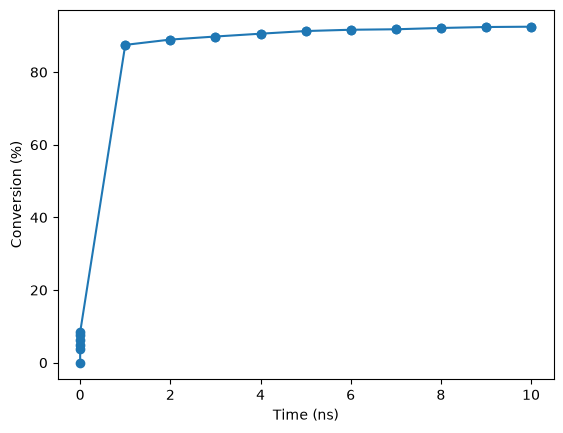

In [16]:
plt.plot(df.groupby('Step').mean()['v_prxn'], 'o-') # Here we average over replicates by grouping same Step values together
plt.xlabel('Time (ns)')
plt.ylabel('Conversion (%)')
plt.show()